In [1]:
import os
import gzip
import time
import struct
import urllib.request
import numpy as np
import matplotlib.pyplot as plt

In [2]:
def download_and_parse_mnist(data_dir="./mnist_data"):
    os.makedirs(data_dir, exist_ok=True)

    base_url = "https://storage.googleapis.com/cvdf-datasets/mnist/"
    files = {
        "train_images": ("train-images-idx3-ubyte.gz", "train-images.idx3-ubyte", "train-images-idx3-ubyte"),
        "train_labels": ("train-labels-idx1-ubyte.gz", "train-labels.idx1-ubyte", "train-labels-idx1-ubyte"),
        "test_images": ("t10k-images-idx3-ubyte.gz", "t10k-images.idx3-ubyte", "t10k-images-idx3-ubyte"),
        "test_labels": ("t10k-labels-idx1-ubyte.gz", "t10k-labels.idx1-ubyte", "t10k-labels-idx1-ubyte"),
    }

    def read_idx_images(filepath, is_gzip=False):
        open_fn = gzip.open if is_gzip else open
        with open_fn(filepath, "rb") as f:
            magic, num, rows, cols = struct.unpack(">IIII", f.read(16))
            if magic != 2051:
                raise ValueError(f"Invalid magic number {magic} in image file: {filepath}")
            data = np.frombuffer(f.read(), dtype=np.uint8)
            return data.reshape(num, rows, cols)

    def read_idx_labels(filepath, is_gzip=False):
        open_fn = gzip.open if is_gzip else open
        with open_fn(filepath, "rb") as f:
            magic, num = struct.unpack(">II", f.read(8))
            if magic != 2049:
                raise ValueError(f"Invalid magic number {magic} in label file: {filepath}")
            return np.frombuffer(f.read(), dtype=np.uint8)

    loaded_data = {}
    for key, (gz_name, raw_name_dot, raw_name_dash) in files.items():
        raw_path_dot = os.path.join(data_dir, raw_name_dot)
        raw_path_dash = os.path.join(data_dir, raw_name_dash)
        gz_path = os.path.join(data_dir, gz_name)

        if os.path.exists(raw_path_dot):
            target_path, is_gz = raw_path_dot, False
        elif os.path.exists(raw_path_dash):
            target_path, is_gz = raw_path_dash, False
        else: 
            if not os.path.exists(gz_path):
                url = base_url + gz_name
                print(f"Downloading {gz_name} from {url} ...")
                urllib.request.urlretrieve(url, gz_path)
            target_path, is_gz = gz_path, True

        if "images" in key:
            loaded_data[key] = read_idx_images(target_path, is_gzip=is_gz)
        else:
            loaded_data[key] = read_idx_labels(target_path, is_gzip=is_gz)

    return (
        loaded_data["train_images"],
        loaded_data["train_labels"],
        loaded_data["test_images"],
        loaded_data["test_labels"],
    )


def one_hot_encode(labels, num_classes):
    one_hot = np.zeros((labels.shape[0], num_classes), dtype=np.float32)
    one_hot[np.arange(labels.shape[0]), labels] = 1.0
    return one_hot                                                                                                                 


X_train_raw, y_train_raw, X_test_raw, y_test_raw = download_and_parse_mnist()

In [ ]:
print("=== Dataset Dimensions ===")
print(f"Number of training samples: {X_train_raw.shape[0]}")
print(f"Number of test samples:     {X_test_raw.shape[0]}")
print(f"Single image shape:         {X_train_raw[0].shape} (height x width)")
print(f"Train images tensor shape:  {X_train_raw.shape}")
print(f"Train labels array shape:   {y_train_raw.shape}")
print(f"Single label shape:         {y_train_raw[0].shape} (scalar class index 0..9)")

=== Dataset Dimensions ===
Number of training samples: 60000
Number of test samples:     10000
Single image shape:         (28, 28) (height x width)
Train images tensor shape:  (60000, 28, 28)
Train labels array shape:   (60000,)
Single label shape:         () (scalar class index 0..9)


In [4]:
num_classes = 10
img_height, img_width = X_train_raw.shape[1], X_train_raw.shape[2]
input_num_elems = img_height * img_width

X_train = X_train_raw.reshape(-1, input_num_elems).astype(np.float32) / 255.0
X_test = X_test_raw.reshape(-1, input_num_elems).astype(np.float32) / 255.0

Y_train = one_hot_encode(y_train_raw, num_classes)
Y_test = one_hot_encode(y_test_raw, num_classes)

print("=== Preprocessed Shapes ===")
print(f"Flattened X_train shape:    {X_train.shape}")
print(f"One-hot Y_train shape:      {Y_train.shape}")
print(f"Single one-hot label shape: {Y_train[0].shape}")

=== Preprocessed Shapes ===
Flattened X_train shape:    (60000, 784)
One-hot Y_train shape:      (60000, 10)
Single one-hot label shape: (10,)


In [5]:
class TwoLayerNeuralNetwork:
    def __init__(self, input_size, hidden_size, output_size, seed=1234):
        rng = np.random.default_rng(seed)
        self.W1 = rng.normal(
            loc=0.0, scale=np.sqrt(2.0 / input_size), size=(input_size, hidden_size)
        ).astype(np.float32)
        self.b1 = np.zeros((1, hidden_size), dtype=np.float32)

        self.W2 = rng.normal(
            loc=0.0, scale=np.sqrt(2.0 / hidden_size), size=(hidden_size, output_size)
        ).astype(np.float32)
        self.b2 = np.zeros((1, output_size), dtype=np.float32)

    @staticmethod
    def relu(z):
        return np.maximum(0.0, z)

    @staticmethod
    def softmax(z):
        shifted_z = z - np.max(z, axis=1, keepdims=True)
        exp_z = np.exp(shifted_z)
        return exp_z / np.sum(exp_z, axis=1, keepdims=True)

    def forward(self, X):
        Z1 = X @ self.W1 + self.b1
        A1 = self.relu(Z1)
        Z2 = A1 @ self.W2 + self.b2
        probs = self.softmax(Z2)
        cache = (X, Z1, A1, Z2, probs)
        return probs, cache

    def backward(self, cache, Y_batch, rate):
        X, Z1, A1, _, probs = cache
        batch = X.shape[0]

        dZ2 = (probs - Y_batch) / batch

        dW2 = A1.T @ dZ2
        db2 = np.sum(dZ2, axis=0, keepdims=True)

        dA1 = dZ2 @ self.W2.T
        dZ1 = dA1 * (Z1 > 0.0)

        dW1 = X.T @ dZ1
        db1 = np.sum(dZ1, axis=0, keepdims=True)

        self.W1 -= rate * dW1
        self.b1 -= rate * db1
        self.W2 -= rate * dW2
        self.b2 -= rate * db2

    def loss(self, X, Y_onehot, y_labels, batch):
        num_samples = X.shape[0]
        total_loss = 0.0
        correct_predictions = 0
        eps = 1e-12

        for start_idx in range(0, num_samples, batch):
            end_idx = min(start_idx + batch, num_samples)
            X_batch = X[start_idx:end_idx]
            Y_batch = Y_onehot[start_idx:end_idx]
            y_true = y_labels[start_idx:end_idx]

            probs, _ = self.forward(X_batch)

            batch_loss = -np.sum(Y_batch * np.log(np.clip(probs, eps, 1.0)))
            total_loss += batch_loss

            predictions = np.argmax(probs, axis=1)
            correct_predictions += np.sum(predictions == y_true)

        avg_loss = total_loss / num_samples
        accuracy = correct_predictions / num_samples
        classification_error = 1.0 - accuracy
        return avg_loss, classification_error, accuracy

In [ ]:
batch = 32
rate = 0.1
hidden_size = 300
num_epochs = 20

model = TwoLayerNeuralNetwork(
    input_size=input_num_elems,
    hidden_size=hidden_size,
    output_size=num_classes,
    seed=1234,
)

In [7]:
num_train = X_train.shape[0]
rng = np.random.default_rng(time.localtime())

print("\n=== Starting Training ===")
print(
    f"Parameters: batch={batch}, lr={rate}, "
    f"hidden_size={hidden_size}, num_epochs={num_epochs}\n"
)

total_start_time = time.perf_counter()

for epoch in range(1, num_epochs + 1):
    epoch_start_time = time.perf_counter()

    shuffled_indices = rng.permutation(num_train)
    X_train_shuffled = X_train[shuffled_indices]
    Y_train_shuffled = Y_train[shuffled_indices]

    for start_idx in range(0, num_train, batch):
        end_idx = min(start_idx + batch, num_train)
        X_batch = X_train_shuffled[start_idx:end_idx]
        Y_batch = Y_train_shuffled[start_idx:end_idx]

        _, cache = model.forward(X_batch)
        model.backward(cache, Y_batch, rate)

    train_loss, train_error, train_acc = model.loss(X_train, Y_train, y_train_raw, batch)
    epoch_duration = time.perf_counter() - epoch_start_time

    print(
        f"Epoch {epoch:2d}/{num_epochs} | "
        f"Train Classification Error: {train_error * 100:5.2f}% | "
        f"Train CE Loss: {train_loss:.4f} | "
        f"Train Accuracy: {train_acc * 100:6.2f}% | "
        f"Time: {epoch_duration:.2f} s"
    )

total_training_time = time.perf_counter() - total_start_time
print(f"\nTotal training time: {total_training_time:.2f} s")


=== Starting Training ===
Parameters: batch=32, lr=0.1, hidden_size=300, num_epochs=10

Epoch  1/10 | Train Classification Error:  4.66% | Train CE Loss: 0.1622 | Train Accuracy:  95.34% | Time: 3.05 s
Epoch  2/10 | Train Classification Error:  2.59% | Train CE Loss: 0.0942 | Train Accuracy:  97.41% | Time: 2.49 s
Epoch  3/10 | Train Classification Error:  2.34% | Train CE Loss: 0.0794 | Train Accuracy:  97.66% | Time: 2.46 s
Epoch  4/10 | Train Classification Error:  1.56% | Train CE Loss: 0.0569 | Train Accuracy:  98.44% | Time: 2.23 s
Epoch  5/10 | Train Classification Error:  1.36% | Train CE Loss: 0.0489 | Train Accuracy:  98.64% | Time: 2.38 s
Epoch  6/10 | Train Classification Error:  0.96% | Train CE Loss: 0.0378 | Train Accuracy:  99.04% | Time: 2.12 s
Epoch  7/10 | Train Classification Error:  0.78% | Train CE Loss: 0.0315 | Train Accuracy:  99.22% | Time: 2.44 s
Epoch  8/10 | Train Classification Error:  0.53% | Train CE Loss: 0.0254 | Train Accuracy:  99.47% | Time: 2.21 s

In [8]:
test_loss, test_error, test_acc = model.loss(X_test, Y_test, y_test_raw, batch)

print("\n=== Final Test Set Evaluation ===")
print(f"Test Classification Error: {test_error * 100:.2f}% ({test_error:.4f})")
print(f"Test Cross-Entropy Loss:   {test_loss:.4f}")
print(f"Test Classification Acc:   {test_acc * 100:.2f}% ({test_acc:.4f})")


=== Final Test Set Evaluation ===
Test Classification Error: 2.07% (0.0207)
Test Cross-Entropy Loss:   0.0625
Test Classification Acc:   97.93% (0.9793)


[[1.7038003e-07 1.1088411e-08 6.9213538e-06 3.1568791e-04 8.3560715e-14
  6.5783961e-06 2.0065363e-14 9.9946064e-01 1.9817352e-07 2.0985094e-04]]


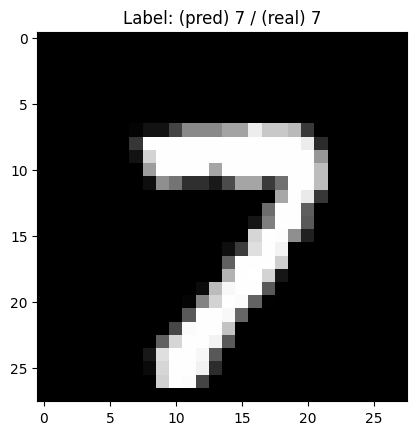

In [9]:
sample_idx = int(rng.random() * 10000)
res, _ = model.forward(X_test[sample_idx])
print(res)
class_idx = np.argmax(res)
real_class_idx = np.argmax(Y_test[sample_idx])
plt.imshow(np.reshape(X_test[sample_idx], shape=(28, 28)), cmap="gray")
plt.title(f"Label: (pred) {class_idx} / (real) {real_class_idx}")
plt.show()